# Методы оптимизации в машинном обучении

### О задании

Настоящее практическое задание посвящено методу градиентного спуска и методу Ньютона. Вам предстоит вывести формулы, реализовать методы оптимизации и провести серии экспериментов.

Задание устроено так: сначала идёт короткий блок теории, а сразу за ним — конкретное задание, для выполнения которого этой теории достаточно. Двигайтесь по порядку: прочитали теорию — выполнили задание — проверили себя тестами — перешли к следующему шагу. Так большое задание распадается на небольшие самостоятельные части.

**Файлы, приложенные к заданию**:

* `optimization.py` — прототипы методов оптимизации: линейный поиск, градиентный спуск, метод Ньютона;
* `oracles.py` — прототипы оракулов (квадратичная функция, логистическая регрессия) и разностных производных;
* `plot_trajectory_2d.py` — утилиты для рисования линий уровня функции и траекторий методов;
* `presubmit_tests.py` — предварительные тесты для самопроверки;
* `data/` — наборы данных *w8a*, *gisette*, *real-sim* для финального эксперимента.

Часть функций уже реализована; те, что нужно реализовать вам, помечены комментариями `# TODO`.

**Как проверять себя по ходу работы.** Тесты запускаются через `pytest` (если он не установлен — `pip install pytest`). После каждого задания запускайте предварительные тесты:

```
python -m pytest presubmit_tests.py
```

Что именно сдавать и как оформлять отчёт — описано в последнем разделе «Оформление и проверка задания».

## Подготовка

Код методов — в `optimization.py` и `oracles.py`, код экспериментов и графиков — в `experiments.py` (чтобы в отчёте было мало кода). Сначала проверим, что реализация проходит предварительные тесты.

In [1]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore', message='The following kwargs were not used by contour')
plt.rcParams.update({'font.size': 11, 'lines.linewidth': 2.5})

import oracles, optimization, experiments

!python -m pytest presubmit_tests.py -q

.............                                                            [100%]
13 passed in 0.59s


# Часть 1. Методы спуска и линейный поиск

## 1.1 Общая схема метода спуска

Рассматриваем задачу гладкой безусловной оптимизации:
$$\underset{x \in \mathbb{R}^n}{\min} \; f(x).$$

Методы спуска итеративно строят последовательность точек $(x_k)_{k=0}^{\infty}$ из $\mathbb{R}^n$ по правилу
$$x_{k+1} = x_k + \alpha_k d_k.$$

Число $k = 0, 1, \ldots$ называется номером итерации метода. Скаляр $\alpha_k \geq 0$ называется длиной шага, а вектор $d_k \in \mathbb{R}^n$ — направлением поиска. В методах спуска требуется, чтобы направление поиска $d_k$ являлось направлением спуска для функции $f$ в точке $x_k$, т. е. удовлетворяло неравенству
$$\langle \nabla f(x_k), d_k \rangle < 0.$$

В этом случае можно гарантировать, что для всех достаточно маленьких $\alpha_k$ значение функции $f$ в новой точке $x_{k+1}$ уменьшится:
$$f(x_{k+1}) < f(x_k).$$

Общая схема метода спуска приведена ниже.

**Алгоритм 1.** Общая схема метода спуска  
**Вход:** начальная точка $x_0$; максимальное число итераций $K$.  
1: **for** $k \leftarrow 0$ **to** $K$ **do**  
2: &nbsp;&nbsp;&nbsp;&nbsp;*(Вызов оракула)* Вычислить $f(x_k)$, $\nabla f(x_k)$ и пр.  
3: &nbsp;&nbsp;&nbsp;&nbsp;*(Критерий остановки)* Если выполнен критерий остановки, то выход.  
4: &nbsp;&nbsp;&nbsp;&nbsp;*(Вычисление направления)* Вычислить направление спуска $d_k$.  
5: &nbsp;&nbsp;&nbsp;&nbsp;*(Линейный поиск)* Найти подходящую длину шага $\alpha_k$.  
6: &nbsp;&nbsp;&nbsp;&nbsp;*(Обновление)* $x_{k+1} \leftarrow x_k + \alpha_k d_k$.  
7: **end for**  
**Выход:** последняя вычисленная точка $x_k$.

## 1.2 Критерий остановки

Идеальным критерием остановки в методе является проверка условия $f(x_k) - f^* < \tilde{\varepsilon}$, где $f^*$ — минимальное значение функции $f$. Такой критерий целесообразно использовать, если оптимальное значение функции известно заранее. К сожалению, зачастую это не так, и поэтому нужно использовать другой критерий.

Наиболее популярным является критерий, основанный на норме градиента:
$$\|\nabla f(x_k)\|_2^2 < \tilde{\varepsilon}.$$

Квадрат здесь ставят за тем, что для «хороших» функций невязка по функции $f(x_k) - f^*$ имеет тот же порядок, что и $\|\nabla f(x_k)\|_2^2$, а не $\|\nabla f(x_k)\|_2$ (например, это верно для сильно выпуклых функций с липшицевым градиентом); так, если $\|\nabla f(x_k)\|_2 \sim 10^{-5}$, то $f(x_k) - f^* \sim 10^{-10}$.

Наконец, для того, чтобы критерий не зависел от того, в каких единицах измеряется функция $f$ (т. е. не изменялся при переходе от функции $f$ к функции $tf$, где $t > 0$), имеет смысл использовать следующий относительный вариант критерия:
$$\|\nabla f(x_k)\|_2^2 \leq \varepsilon \|\nabla f(x_0)\|_2^2, \tag{1.1}$$
где $\varepsilon \in (0, 1)$ — заданная относительная точность. Критерий остановки (1.1) гарантирует, что метод уменьшит начальную невязку $\|\nabla f(x_0)\|_2$ в $\varepsilon^{-1}$ раз.

**Во всех методах этого задания нужно использовать именно критерий остановки (1.1).**

## 1.3 Линейный поиск

Рассматривается функция
$$\varphi_k(\alpha) := f(x_k + \alpha d_k).$$
Заметим, что
$$\varphi'_k(\alpha) = \langle \nabla f(x_k + \alpha d_k), d_k \rangle.$$
Поскольку $d_k$ является направлением спуска, то $\varphi'_k(0) = \langle \nabla f(x_k), d_k \rangle < 0$.

**Условием Армихо** для $\alpha$ называется выполнение следующего неравенства:
$$\varphi_k(\alpha) \leq \varphi_k(0) + c_1 \alpha \varphi'_k(0),$$
где $c_1 \in (0, 0.5)$ — некоторая константа.

Для поиска точки $\alpha$, удовлетворяющей условию Армихо, обычно используют метод дробления шага (бэктрекинг):

**Алгоритм 2.** Метод дробления шага  
**Вход:** функция $\varphi_k: \mathbb{R}_+ \to \mathbb{R}$; начальная точка $\alpha_k^{(0)}$.  
1: $\alpha \leftarrow \alpha_k^{(0)}$.  
2: **while** $\varphi_k(\alpha) > \varphi_k(0) + c_1 \alpha \varphi'_k(0)$ **do**  
3: &nbsp;&nbsp;&nbsp;&nbsp;$\alpha \leftarrow \alpha / 2$.  
4: **end while**  
**Выход:** $\alpha$.

«Адаптивный» метод подбора шага запоминает величину $\alpha_k$, найденную на текущей итерации, и на следующей итерации начинает процедуру дробления с $\alpha_{k+1}^{(0)} := 2\alpha_k$. Исключение здесь составляют ньютоновские и квазиньютоновские методы — в этих методах процедуру дробления шага всегда нужно начинать с $\alpha_k^{(0)} := 1$.

**Сильные условия Вульфа:**
$$\varphi_k(\alpha) \leq \varphi_k(0) + c_1 \alpha \varphi'_k(0),$$
$$|\varphi'_k(\alpha)| \leq c_2 |\varphi'_k(0)|,$$
где $c_1 \in (0, 0.5)$, $c_2 \in (c_1, 1)$.

Самостоятельно реализовывать схему для сильных условий Вульфа не нужно — используйте библиотечную функцию `line_search` из модуля `scipy.optimize`: она реализует поиск шага по сильным условиям Вульфа. В ней начальная длина шага $\alpha_k^{(0)}$ автоматически выбирается равной 1.

### Задание 1. Линейный поиск — файл `optimization.py`

**Что нужно сделать.** Реализуйте метод `line_search` класса `LineSearchTool` — процедуру подбора длины шага $\alpha_k$ для заданной точки $x_k$ и направления спуска $d_k$. Метод должен поддерживать три стратегии (поле `method`):

* `'Constant'` — постоянный шаг: просто вернуть фиксированное значение `c`;
* `'Armijo'` — метод дробления шага (Алгоритм 2). Стартовое значение шага: `previous_alpha`, если оно передано, иначе `alpha_0`;
* `'Wolfe'` — сильные условия Вульфа: воспользуйтесь библиотечной функцией `scipy.optimize.line_search`, передав ей `c1` и `c2` из параметров объекта. Функция принимает саму функцию и её градиент (`oracle.func` и `oracle.grad`), а также точку `x_k` и направление `d_k`; найденный шаг лежит в поле `.alpha` возвращаемого результата (в старых версиях scipy возвращается кортеж, и шаг — это элемент с индексом 0).

**Важно.** У `scipy.optimize.line_search` есть один недостаток: она иногда не сходится, и в возвращаемом результате `alpha` оказывается равным `None`. Если это произошло, запустите процедуру дробления шага для поиска точки, удовлетворяющей условию Армихо (т. е. сделайте переход к стратегии `'Armijo'`).

В стратегиях Армихо (и в fallback после Вульфа) значения функции и её производной вдоль направления $\varphi_k(\alpha)$ вычисляйте через методы оракула `func_directional` и `grad_directional` — они уже реализованы в базовом классе `BaseSmoothOracle`.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_line_search
```

## 1.4 Градиентный спуск

Градиентный спуск
$$x_{k+1} = x_k - \alpha_k \nabla f(x_k)$$
можно рассматривать как метод спуска, в котором направление поиска $d_k$ равно антиградиенту $-\nabla f(x_k)$, а длина шага $\alpha_k$ выбирается с помощью линейного поиска.

### Задание 2. Градиентный спуск — файл `optimization.py`

**Что нужно сделать.** Реализуйте функцию `gradient_descent` — градиентный спуск по общей схеме из раздела 1.1:

* **направление:** $d_k = -\nabla f(x_k)$;
* **шаг:** $\alpha_k$ подбирается объектом `LineSearchTool` (задание 1). Используйте адаптивный подбор шага из раздела 1.3: на итерации $k \geq 1$ передавайте в линейный поиск `previous_alpha=2 * alpha_{k-1}`;
* **критерий остановки:** критерий (1.1), т. е. $\|\nabla f(x_k)\|_2^2 \leq \text{tolerance} \cdot \|\nabla f(x_0)\|_2^2$. Проверяйте его в начале каждой итерации;
* **превышение числа итераций:** если после `max_iter` итераций критерий так и не выполнен, возвращайте сообщение `'iterations_exceeded'`;
* **ошибки вычислений:** если в процессе вычислений появились значения `None`, `inf` или `nan` (например, из-за переполнения), возвращайте сообщение `'computational_error'`.

Функция возвращает кортеж `(x_star, message, history)`. Форматы возвращаемых значений и структура словаря `history` при `trace=True` подробно описаны в docstring функции — следуйте им. Не забудьте про параметр `display` для отладочного вывода.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_gd_basic presubmit_tests.py::test_gd_1d
```

# Часть 2. Эксперименты с градиентным спуском

В этой части проводятся эксперименты с реализованным градиентным спуском на квадратичных функциях. Оракул квадратичной функции `QuadraticOracle` уже полностью реализован в модуле `oracles`. Он соответствует функции
$$f(x) = \frac{1}{2}\langle Ax, x \rangle - \langle b, x \rangle, \qquad A \in S_{++}^n, \; b \in \mathbb{R}^n.$$

Для рисования линий уровня функции используйте функцию `plot_levels`, а для рисования траекторий метода — функцию `plot_trajectory` из файла `plot_trajectory_2d.py`.

Результаты экспериментов из этой и следующих частей оформляйте в отчёте (требования к отчёту — в последнем разделе).

### Задание 3. Эксперимент: траектория градиентного спуска на квадратичной функции

**Что нужно сделать.** Придумайте две-три квадратичные **двумерные** функции, на которых работа градиентного спуска будет заметно отличаться (например, с разным числом обусловленности). Для каждой из них запустите градиентный спуск из нескольких начальных точек и с разными стратегиями выбора шага (константная, Армихо, Вульф). Нарисуйте графики с линиями уровня функций и траекториями методов (функции `plot_levels` и `plot_trajectory`).

**Вопрос для анализа.** Как отличается поведение метода в зависимости от числа обусловленности функции, выбора начальной точки и стратегии выбора шага? Ответьте на него в отчёте.

### Решение задания 3

**Описание эксперимента.** Рассматриваются три двумерные квадратичные функции $f(x) = \frac12 \langle Ax, x\rangle$ ($b = 0$, минимум $x^* = 0$, $f^* = 0$):

| функция | матрица $A$ | собственные числа | $\kappa = L/\mu$ |
|---|---|---|---|
| 1 | $\mathrm{Diag}(1, 2)$ | 1, 2 | 2 |
| 2 | $\mathrm{Diag}(1, 20)$ | 1, 20 | 20 |
| 3 | $R_{45°}\,\mathrm{Diag}(1, 9)\,R_{45°}^T = \begin{pmatrix}5 & -4\-4 & 5\end{pmatrix}$ | 1, 9 | 9 |

Третья функция — та же «вытянутая» парабола, но с осями эллипсов, повёрнутыми на $45°$ относительно координатных осей.

Для каждой функции градиентный спуск запускается из трёх начальных точек: $x_0 = (-5, 4)$, $(5, 1)$ и $(5, 0)$ — последняя лежит на собственном векторе $e_1$ матриц функций 1–2 (на «оси» эллипса). Стратегии выбора шага:

* `Constant` с $c = 1/L$ — классический безопасный шаг ($L = \lambda_{\max}(A)$);
* `Constant` с $c = 1.9/L$ — шаг близок к границе устойчивости $2/L$;
* `Armijo` — дробление шага, $c_1 = 10^{-4}$, $\alpha_0 = 1$, адаптивный старт $2\alpha_{k-1}$;
* `Wolfe` — сильные условия Вульфа, $c_1 = 10^{-4}$, $c_2 = 0.9$ (`scipy.optimize.line_search`).

Точность: `tolerance` $= 10^{-8}$ в критерии (1.1). На графиках — линии уровня функции и траектории; в легенде указано число итераций, ниже — сводная таблица.


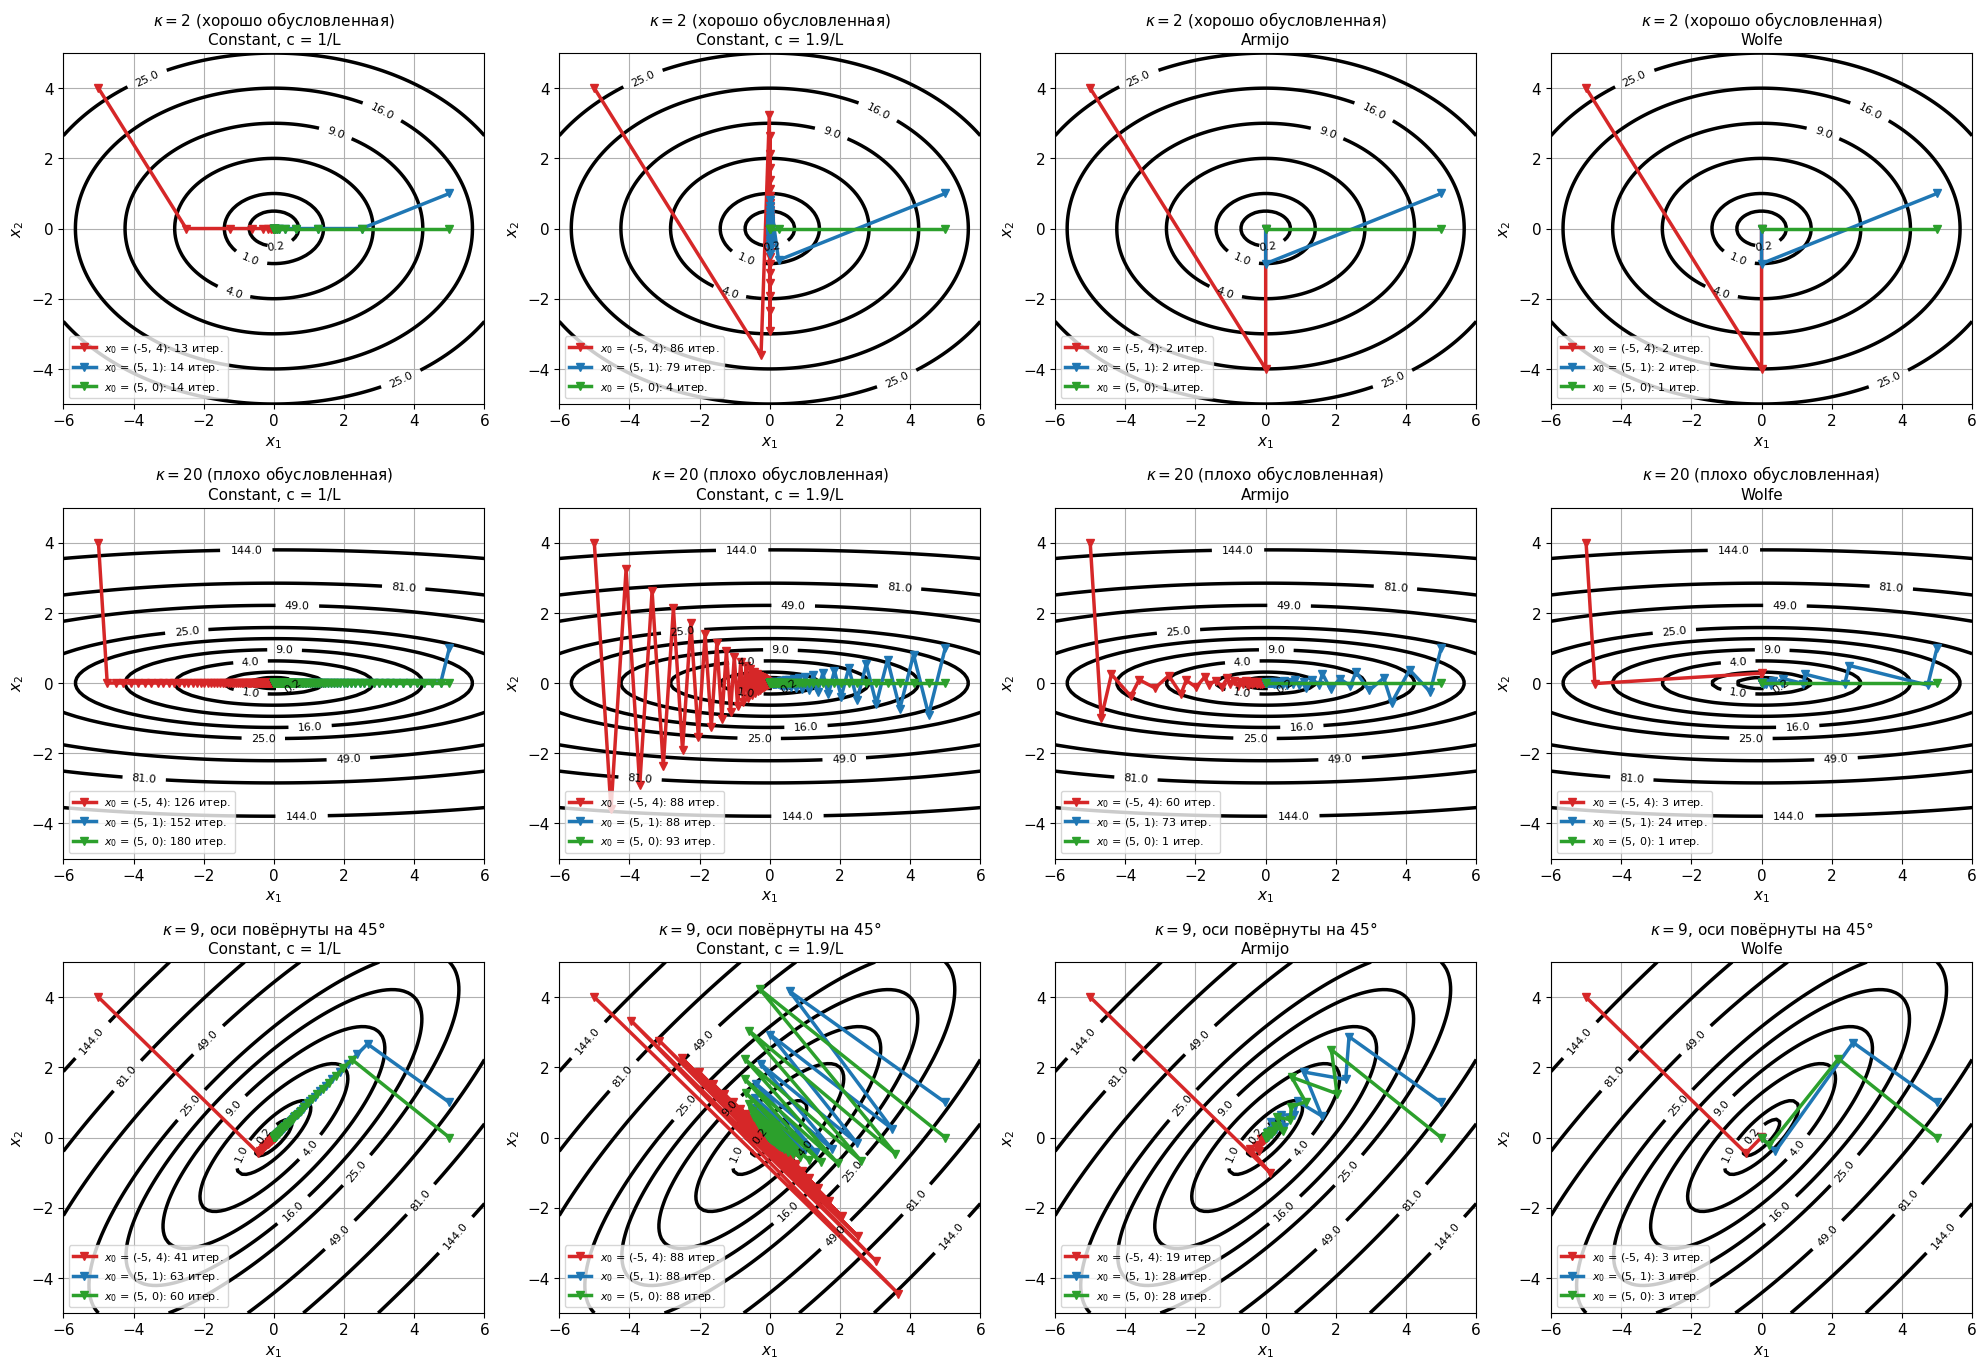

In [2]:
table = experiments.run_task3()

In [3]:
import pandas as pd
starts = ['x0 = ({:g}, {:g})'.format(*x) for x in experiments.TASK3_STARTS]
pd.DataFrame(table, index=starts).T.rename_axis(['функция', 'шаг'])

x0 = (-5, 4)  \
функция                             шаг                                 
$\kappa = 2$ (хорошо обусловленная) Constant, c = 1/L              13   
                                    Constant, c = 1.9/L            86   
                                    Armijo                          2   
                                    Wolfe                           2   
$\kappa = 20$ (плохо обусловленная) Constant, c = 1/L             126   
                                    Constant, c = 1.9/L            88   
                                    Armijo                         60   
                                    Wolfe                           3   
$\kappa = 9$, оси повёрнуты на 45°  Constant, c = 1/L              41   
                                    Constant, c = 1.9/L            88   
                                    Armijo                         19   
                                    Wolfe                           3   

                                                         x0 = (5, 1)  \
функция                             шаг                                
$\kappa = 2$ (хорошо обусловленная) Constant, c = 1/L             14   
                                    Constant, c = 1.9/L           79   
                                    Armijo                         2   
                                    Wolfe                          2   
$\kappa = 20$ (плохо обусловленная) Constant, c = 1/L            152   
                                    Constant, c = 1.9/L           88   
                                    Armijo                        73   
                                    Wolfe                         24   
$\kappa = 9$, оси повёрнуты на 45°  Constant, c = 1/L             63   
                                    Constant, c = 1.9/L           88   
                                    Armijo                        28   
                                    Wolfe                          3   

                                                         x0 = (5, 0)  
функция                             шаг                               
$\kappa = 2$ (хорошо обусловленная) Constant, c = 1/L             14  
                                    Constant, c = 1.9/L            4  
                                    Armijo                         1  
                                    Wolfe                          1  
$\kappa = 20$ (плохо обусловленная) Constant, c = 1/L            180  
                                    Constant, c = 1.9/L           93  
                                    Armijo                         1  
                                    Wolfe                          1  
$\kappa = 9$, оси повёрнуты на 45°  Constant, c = 1/L             60  
                                    Constant, c = 1.9/L           88  
                                    Armijo                        28  
                                    Wolfe                          3

**Результаты и выводы.**

*Число обусловленности.* Для функции $f(x) = \frac12\langle Ax, x\rangle$ градиентный спуск с шагом $\alpha$ действует на каждую компоненту $x$ в собственном базисе $A$ как умножение на $(1 - \alpha\lambda_i)$. Поэтому скорость определяется самым «медленным» множителем $q = \max_i |1 - \alpha\lambda_i|$. При $\alpha = 1/L$ это $q = 1 - 1/\kappa$: чем больше $\kappa$, тем медленнее сходимость. Таблица это подтверждает количественно: для $\kappa = 20$ из $x_0 = (5, 0)$ (вся невязка — вдоль медленного направления $\lambda = 1$) требуется $T \approx \frac{\ln(10^{8})}{2\,|\ln 0.95|} \approx 180$ итераций — ровно столько и получилось; для $\kappa = 2$ ($q = 0.5$) — 14 итераций. Геометрически при большом $\kappa$ линии уровня сильно вытянуты, антиградиент смотрит почти поперёк «оврага», и траектория либо медленно ползёт вдоль дна (шаг $1/L$), либо зигзагует между стенками (Армихо, $1.9/L$).

*Константный шаг.* При $c = 1.9/L$ быстрая компонента умножается на $1 - 1.9 = -0.9$: метод «перепрыгивает» минимум вдоль крутого направления, отсюда характерный зигзаг на графиках. Почти для всех запусков это даёт одно и то же число итераций $\approx \frac{\ln 10^8}{2|\ln 0.9|} \approx 88$, не зависящее ни от $\kappa$, ни от начальной точки, — потому что теперь узкое место именно крутое направление, а не пологое. Исключение — $\kappa = 2$, $x_0 = (5,0)$: там крутой компоненты нет вовсе и множитель $|1 - 0.95| = 0.05$ даёт 4 итерации. При $c > 2/L$ метод бы расходился. Константный шаг требует знать $L$ и не адаптируется к задаче.

*Адаптивные стратегии (Армихо, Вульф)* почти везде быстрее константного шага. Но очень маленькие числа итераций (1–3) в таблице отчасти **артефакт** выбора функций: первый пробный шаг $\alpha = 1$ совпадает с $1/\lambda_{\min} = 1$ и за одну итерацию полностью «убивает» компоненту вдоль медленного направления, после чего задача становится одномерной. Дробление $\alpha$ пополам (Армихо) и интерполяция в `scipy` (Вульф) затем быстро находят точный шаг $1/\lambda_{\max}$. Метод Вульфа, подбирающий шаг близко к точной минимизации вдоль луча, устойчиво даёт 2–3 итерации (кроме $\kappa = 20$, $x_0 = (5,1)$ — 24 итерации). Армихо при $\kappa = 20$ и $\kappa = 9$ принимает слишком длинные шаги (условие Армихо с $c_1 = 10^{-4}$ очень слабое) и зигзагует: 19–73 итерации.

*Начальная точка.* Если $x_0 - x^*$ — собственный вектор $A$ (точка $(5, 0)$ для функций 1–2), то антиградиент направлен точно в минимум, и адаптивный линейный поиск сходится за 1 итерацию. Для повёрнутой функции 3 та же точка уже не лежит на оси эллипса, и метод ведёт себя так же, как из любой другой точки. Сам градиентный спуск инвариантен к повороту системы координат: функция 3 — это «та же» функция с $\kappa = 9$, поворот лишь меняет, какие начальные точки оказываются на осях. Чем больше доля невязки вдоль медленного направления, тем дольше работает метод (например, при $c = 1/L$, $\kappa = 20$: 126 → 152 → 180 итераций для трёх точек).


### Задание 4. Эксперимент: число итераций градиентного спуска в зависимости от числа обусловленности и размерности

**Что нужно сделать.** Исследуйте, как зависит число итераций $T(n, \kappa)$, необходимое градиентному спуску для сходимости (успешному выходу по критерию остановки), от двух параметров: 1) числа обусловленности $\kappa \geq 1$ оптимизируемой функции и 2) размерности пространства $n$.

Для заданных $n$ и $\kappa$ сгенерируйте случайную квадратичную задачу размера $n$ с числом обусловленности $\kappa$ и запустите на ней градиентный спуск с некоторой фиксированной требуемой точностью. Замерьте число итераций, которое потребовалось методу до сходимости.

Схема эксперимента. Зафиксируйте значение размерности $n$. Переберите различные числа обусловленности $\kappa$ по сетке и постройте график зависимости $T(n, \kappa)$ от $\kappa$. Поскольку каждый раз квадратичная задача генерируется случайным образом, повторите эксперимент несколько раз — в итоге для фиксированного $n$ получится целое семейство кривых, нарисуйте их все одним цветом (например, красным). Теперь увеличьте $n$ и повторите эксперимент: новое семейство кривых нарисуйте другим цветом (например, синим). Повторите процедуру для нескольких значений $n$. Какие выводы можно сделать из полученной картинки?

**Рекомендация.** Проще всего сгенерировать случайную квадратичную задачу размера $n$ с числом обусловленности $\kappa$ следующим образом. В качестве матрицы $A \in S_{++}^n$ удобно взять просто диагональную матрицу $A = \mathrm{Diag}(a)$, у которой диагональные элементы сгенерированы случайно в пределах $[1, \kappa]$, причём $\min(a) = 1$, $\max(a) = \kappa$. В качестве вектора $b \in \mathbb{R}^n$ можно взять вектор со случайными элементами. Диагональные матрицы удобно рассматривать, поскольку с ними можно эффективно работать даже при больших значениях $n$; рекомендуется хранить матрицу $A$ в формате разреженной диагональной матрицы (см. `scipy.sparse.diags`).

Обратите внимание, что значения размерности $n$ имеет смысл перебирать по логарифмической сетке (например, $n = 10$, $n = 100$, $n = 1000$ и т. д.). Если вы используете случайность — зафиксируйте `seed`, чтобы результат был воспроизводимым.

### Решение задания 4

**Описание эксперимента.** Для каждой пары $(n, \kappa)$ генерируется случайная квадратичная задача $f(x) = \frac12\langle Ax, x\rangle - \langle b, x\rangle$:

* $A = \mathrm{Diag}(a)$ хранится как `scipy.sparse.diags`; $a_i \sim U[1, \kappa]$, затем $a_1 := 1$, $a_n := \kappa$, так что $\min(a) = 1$, $\max(a) = \kappa$ и число обусловленности ровно $\kappa$;
* $b \sim \mathcal N(0, I_n)$; начальная точка $x_0 = 0$.

Параметры: $n \in \{10, 100, 1000, 10000\}$ (логарифмическая сетка), $\kappa$ — 21 значение равномерно на $[1, 1000]$, для каждого $n$ — 5 случайных реализаций (кривых); `tolerance` $= 10^{-6}$, `max_iter` $= 10^5$, `seed = 0`. Градиентный спуск запускается с двумя стратегиями линейного поиска: `Armijo` и `Wolfe` (параметры по умолчанию). Измеряется число итераций $T(n, \kappa)$ до выполнения критерия (1.1). Кривые одного $n$ — одного цвета.


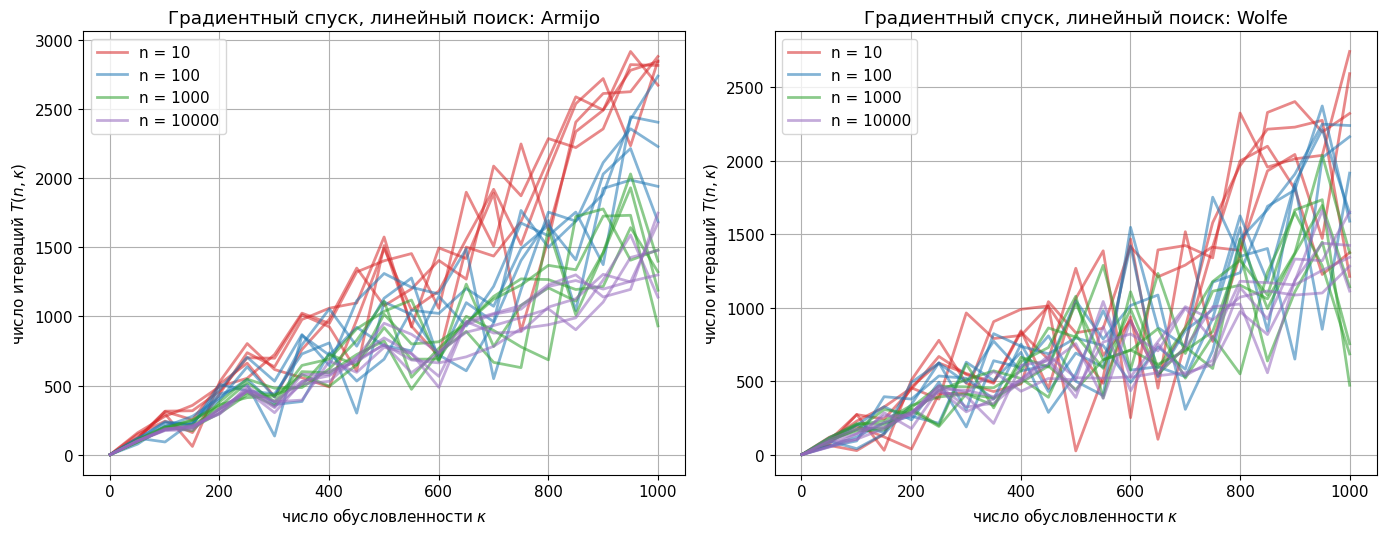

In [4]:
ns = [10, 100, 1000, 10000]
kappas = np.linspace(1, 1000, 21)
results4 = {method: experiments.run_task4(ns, kappas, n_seeds=5, method=method, seed=0)
            for method in ['Armijo', 'Wolfe']}
experiments.plot_task4(ns, kappas, results4)

**Результаты и выводы.**

1. **Число итераций растёт примерно линейно по $\kappa$.** Это согласуется с теорией: для сильно выпуклой функции с липшицевым градиентом градиентный спуск сходится линейно со знаменателем $q \approx 1 - c/\kappa$, поэтому для достижения точности $\varepsilon$ нужно $T = O(\kappa \log \frac1\varepsilon)$ итераций. При $\kappa = 1$ ($A = I$) метод сходится за одну итерацию.

2. **Размерность почти не влияет на $T$**: семейства кривых для $n = 10$ и $n = 10\,000$ лежат рядом, хотя $n$ изменилось в $1000$ раз. Оценка скорости зависит только от спектральных границ $\mu = 1$, $L = \kappa$, а не от $n$. Стоимость одной итерации растёт как $O(n)$ (диагональная матрица), но число итераций — нет.

3. **Небольшой эффект от $n$ всё же есть, и он обратный ожидаемому**: при малых $n$ итераций больше (при $\kappa = 1000$ ≈2800 для $n=10$ против ≈1400 для $n = 10^4$ у Армихо). Причина — относительный критерий (1.1). Начальный градиент $\nabla f(0) = -b$, на медленную компоненту ($\lambda = 1$) приходится в среднем доля $\approx 1/n$ от $\|b\|^2$. Медленную компоненту нужно уменьшить лишь до уровня $\varepsilon \|b\|^2$, т.е. в $\sim \varepsilon n$ раз по квадрату нормы, и $T \approx \frac\kappa2 \ln\frac{1}{n\varepsilon}$. Для $\varepsilon = 10^{-6}$ отношение $\ln(10^5)/\ln(10^2) = 2.5$ — того же порядка, что и наблюдаемая разница.

4. **Разброс кривых.** При малых $n$ случайность задачи сильнее (доля медленной компоненты $b_1^2/\|b\|^2$ сильно флуктуирует), поэтому красные кривые разбросаны больше. Линейный поиск Вульфа даёт более «шумные» кривые, чем Армихо: иногда удачный шаг почти точно гасит медленную компоненту, и метод сходится быстрее (провалы на графике), а в среднем числа итераций у двух стратегий близки.


# Часть 3. Метод Ньютона

Метод Ньютона:
$$x_{k+1} = x_k - \alpha_k [\nabla^2 f(x_k)]^{-1} \nabla f(x_k).$$

Для метода Ньютона очень важно использовать единичный шаг $\alpha_k = 1$, чтобы обеспечить локальную квадратичную сходимость. Поэтому в алгоритмах линейного поиска нужно всегда первым делом пробовать единичный шаг. Теория гарантирует, что в зоне квадратичной сходимости метода Ньютона единичный шаг будет удовлетворять условиям Армихо/Вульфа и поэтому будет приниматься автоматически. Если единичный шаг не удовлетворяет условиям Армихо/Вульфа, то алгоритмы линейного поиска его уменьшат и тем самым обеспечат глобальную сходимость метода Ньютона.

Вычисление ньютоновского направления $d_k = -[\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$ эквивалентно решению линейной системы уравнений
$$\nabla^2 f(x_k)\, d_k = -\nabla f(x_k).$$
Если гессиан — положительно определённая матрица ($\nabla^2 f(x_k) \succ 0$), то предпочтительным методом решения такой системы является разложение Холецкого: как и метод Гаусса, оно работает за $O(n^3)$, но является вычислительно более эффективным. Если матрица системы не является положительно определённой, то разложение Холецкого сможет обнаружить это и сообщить (бросить исключение).

### Задание 5. Метод Ньютона — файл `optimization.py`

**Что нужно сделать.** Реализуйте функцию `newton` по аналогии с `gradient_descent` из задания 2. Отличия:

* **направление:** $d_k = -[\nabla^2 f(x_k)]^{-1} \nabla f(x_k)$. Для его вычисления решайте линейную систему $\nabla^2 f(x_k)\, d_k = -\nabla f(x_k)$;
* **линейный поиск:** на каждой итерации начинайте подбор шага с единичного, $\alpha_k^{(0)} = 1$ (см. теорию выше);
* **новое сообщение об ошибке:** если гессиан в текущей точке не оказался положительно определённым и систему не удалось решить, возвращайте `'newton_direction_error'`.

Остальное — критерий остановки (1.1), заполнение `history` при `trace=True`, сообщения `'iterations_exceeded'` и `'computational_error'` — так же, как в градиентном спуске; точные форматы описаны в docstring функции.

**Важно.** Для поиска направления не нужно обращать гессиан в явном виде (функция `np.linalg.inv`) и не нужно использовать самый общий метод решения системы линейных уравнений (`numpy.linalg.solve`). Учтите тот факт, что в рассматриваемой задаче гессиан является симметричной положительно определённой матрицей, и воспользуйтесь разложением Холецкого (функции `scipy.linalg.cho_factor` и `scipy.linalg.cho_solve`).

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_newton_basic presubmit_tests.py::test_newton_1d presubmit_tests.py::test_newton_fail
```

# Часть 4. Логистическая регрессия

## 4.1 Двухклассовая логистическая регрессия

Логистическая регрессия является стандартной моделью в задачах классификации. Для простоты рассмотрим лишь случай бинарной классификации. Неформально задача формулируется следующим образом. Имеется обучающая выборка $(a_i, b_i)_{i=1}^m$, состоящая из $m$ векторов $a_i \in \mathbb{R}^n$ (называемых признаками) и соответствующих им чисел $b_i \in \{-1, 1\}$ (называемых классами). Нужно построить алгоритм $b(\cdot)$, который для произвольного нового вектора признаков $a$ автоматически определит его класс $b(a) \in \{-1, 1\}$.

В модели логистической регрессии определение класса выполняется по знаку линейной комбинации компонент вектора $a$ с некоторыми фиксированными коэффициентами $x \in \mathbb{R}^n$:
$$b(a) := \mathrm{sign}(\langle a, x \rangle).$$

Коэффициенты $x$ являются параметрами модели и настраиваются с помощью решения следующей оптимизационной задачи:
$$\underset{x \in \mathbb{R}^n}{\min} \left( \frac{1}{m} \sum_{i=1}^m \ln(1 + \exp(-b_i \langle a_i, x \rangle)) + \frac{\lambda}{2} \|x\|_2^2 \right),$$
где $\lambda > 0$ — коэффициент регуляризации (параметр модели).

### Задание 6. Формулы для функции, градиента и гессиана — в отчёт

**Что нужно сделать.** Получите формулы для градиента и гессиана функции логистической регрессии из раздела 4.1. Выпишите их в отчёт **в матрично-векторной форме**, с использованием поэлементных функций, но без каких-либо суммирований. Также выпишите в отчёт выражение для самой функции логистической регрессии в матрично-векторной форме (без явных суммирований).

**Замечание.** В матрично-векторной форме допускается использование операций матричного сложения/произведения, умножения на скаляр, транспонирования, стандартного скалярного произведения, поэлементного произведения, а также применения ко всем элементам вектора некоторой скалярной функции. Кроме этого, допускается использование стандартных матриц/векторов (заданного размера): единичная матрица $I_n$, нулевая матрица $0_{m \times n}$, нулевой вектор $0_n$, вектор из всех единиц $1_n := (1, \ldots, 1)$.

Свои выкладки можно сверить со справкой, приведённой ниже.


### Решение задания 6: вывод формул

Пусть $A \in \mathbb{R}^{m \times n}$ — матрица, строки которой — объекты $a_i^T$, $b \in \{-1,1\}^m$. Обозначим $z := b \odot (Ax)$, т.е. $z_i = b_i\langle a_i, x\rangle$, и $\sigma(t) = \frac{1}{1+e^{-t}}$; скалярные функции применяются к векторам поэлементно.

**Функция.** Так как $\sum_{i=1}^m \ln(1 + e^{-z_i}) = \mathbf{1}_m^T \ln(1 + e^{-z})$,
$$f(x) = \frac1m\, \mathbf 1_m^T \ln\big(1 + \exp(-b \odot Ax)\big) + \frac\lambda2\, x^T x.$$

**Градиент.** Для одного слагаемого $\ell(t) = \ln(1+e^{-t})$: $\ell'(t) = -\frac{e^{-t}}{1+e^{-t}} = -\sigma(-t)$. Дифференциал:
$$d f = \frac1m \sum_i \ell'(z_i)\, dz_i + \lambda x^T dx, \qquad dz = b \odot (A\,dx) = \mathrm{Diag}(b) A\, dx.$$
Значит, $df = \frac1m\big(\ell'(z)\big)^T \mathrm{Diag}(b) A\,dx + \lambda x^T dx = \big\langle \frac1m A^T (b \odot \ell'(z)) + \lambda x,\ dx\big\rangle$, откуда
$$\nabla f(x) = -\frac1m\, A^T\big(b \odot \sigma(-b \odot Ax)\big) + \lambda x.$$

**Гессиан.** $\frac{d}{dt}\sigma(-t) = -\sigma(-t)\big(1 - \sigma(-t)\big)$. Дифференцируем градиент:
$$d\nabla f = -\frac1m A^T\Big(b \odot \big[-\sigma(-z)\odot(1-\sigma(-z))\big] \odot dz\Big) + \lambda\,dx = \frac1m A^T \Big(s \odot b \odot b \odot (A\,dx)\Big) + \lambda\, dx,$$
где $s := \sigma(-z) \odot (1 - \sigma(-z))$. Так как $b_i^2 = 1$, получаем
$$\nabla^2 f(x) = \frac1m\, A^T \mathrm{Diag}\big(\sigma(-b\odot Ax) \odot (1 - \sigma(-b \odot Ax))\big)\, A + \lambda I_n.$$

Заметим, что $0 < s_i \le \frac14$, поэтому $\lambda I_n \preceq \nabla^2 f(x) \preceq \big(\frac{1}{4m}\lambda_{\max}(A^TA) + \lambda\big) I_n$: функция $\lambda$-сильно выпукла, гессиан всегда положительно определён, и метод Ньютона корректно определён (разложение Холецкого всегда существует). Формулы совпадают со справкой ниже.


## Справка: функция, градиент и гессиан логистической регрессии

Ниже приведены формулы из задания 6 — пользуйтесь ими как шпаргалкой при реализации оракула (задание 7).

Обозначим $z := b \odot (Ax) \in \mathbb{R}^m$, где $\odot$ — поэлементное умножение, а все скалярные функции ($\ln$, $\exp$, $\sigma$) применяются к векторам поэлементно. Тогда

$$f(x) = \frac{1}{m}\, \mathbf{1}_m^T \ln\!\big(1 + e^{-z}\big) + \frac{\lambda}{2} \|x\|_2^2,$$

$$\nabla f(x) = -\frac{1}{m}\, A^T \big( b \odot \sigma(-z) \big) + \lambda x, \qquad \sigma(t) := \frac{1}{1 + e^{-t}},$$

$$\nabla^2 f(x) = \frac{1}{m}\, A^T\, \operatorname{Diag}(s)\, A + \lambda I_n, \qquad s := \sigma(-z) \odot \big(1 - \sigma(-z)\big).$$

**Как считать это в numpy/scipy (без переполнений и с поддержкой разреженных матриц):**

* $\ln(1 + e^{-z})$ — функция `np.logaddexp(0, -z)`: она эквивалентна «в лоб», но не переполняется при больших $|z|$;
* сигмоида $\sigma(z)$ — функция `scipy.special.expit(z)`;
* произведения $Ax$ и $A^T y$ — методы `A.dot(x)` и `A.T.dot(y)`: они одинаково работают и для плотных матриц `np.array`, и для разреженных `scipy.sparse.csr_matrix`;
* в гессиане произведение $A^T\, \operatorname{Diag}(s)\, A$ не нужно считать через явную диагональную матрицу — достаточно поэлементно домножить строки $A$ на вектор $s$: для плотной матрицы это `A * s[:, None]`, для разреженной — метод `A.multiply(s[:, None])` (тип матрицы проверяется функцией `scipy.sparse.issparse`);
* слагаемое $\lambda I_n$ — это `regcoef * np.eye(n)`.

## 4.2 Разностная проверка градиента и гессиана

Проверить правильность реализации подсчёта градиента можно с помощью конечных разностей:
$$[\nabla f(x)]_i \approx \frac{f(x + \varepsilon_1 e_i) - f(x)}{\varepsilon_1},$$
где $e_i := (0, \ldots, 0, 1, 0, \ldots, 0)$ — $i$-й базисный орт, а $\varepsilon_1$ — достаточно маленькое положительное число: $\varepsilon_1 \sim \sqrt{\varepsilon_{mach}}$, где $\varepsilon_{mach}$ — машинная точность ($\approx 10^{-16}$ для типа `double`).

Вторые производные:
$$[\nabla^2 f(x)]_{ij} \approx \frac{f(x + \varepsilon_2 e_i + \varepsilon_2 e_j) - f(x + \varepsilon_2 e_i) - f(x + \varepsilon_2 e_j) + f(x)}{\varepsilon_2^2},$$
здесь $\varepsilon_2 \sim \sqrt[3]{\varepsilon_{mach}}$.

### Задание 7. Оракул логистической регрессии и разностные производные — файл `oracles.py`

**Что нужно сделать.**

1. Реализуйте оракул логистической регрессии: методы `func`, `grad` и `hess` класса `LogRegL2Oracle` (используйте формулы из задания 6). Оракул создаётся напрямую по данным: `LogRegL2Oracle(A, b, regcoef)`.
2. Реализуйте функции `grad_finite_diff` и `hess_finite_diff` — разностные аппроксимации градиента и гессиана (формулы из раздела 4.2).
3. Проверьте правильность реализации оракула: сгенерируйте небольшую модельную выборку (матрицу $A$ и вектор $b$) и сравните значения, выдаваемые методами `grad` и `hess`, с соответствующими разностными аппроксимациями в нескольких пробных точках $x$. Эту проверку удобно оформить отдельной ячейкой и привести в отчёте.

**Замечания.**

* Реализация оракула должна быть полностью векторизованной, т. е. код не должен содержать никаких циклов по элементам выборки.
* Ваш код должен поддерживать как плотные матрицы $A$ типа `np.array`, так и разреженные типа `scipy.sparse.csr_matrix` (конкретные приёмы — в справке выше).
* Нигде в промежуточных вычислениях не стоит вычислять значение $\exp(-b_i \langle a_i, x \rangle)$, иначе может произойти переполнение. Вместо этого следует напрямую вычислять необходимые величины с помощью специализированных функций: `np.logaddexp` для $\ln(1 + \exp(\cdot))$ и `scipy.special.expit` для $1 / (1 + \exp(\cdot))$.

**Как проверить себя:**

```
python -m pytest presubmit_tests.py::test_log_reg_usual presubmit_tests.py::test_grad_finite_diff_1 presubmit_tests.py::test_grad_finite_diff_2 presubmit_tests.py::test_hess_finite_diff_1 presubmit_tests.py::test_hess_finite_diff_2
```

### Решение задания 7: проверка оракула

Оракул `LogRegL2Oracle` реализован полностью векторизованно (без циклов по объектам), работает и с `np.array`, и с `scipy.sparse.csr_matrix`. Генерируем модельную выборку $A \in \mathbb{R}^{60 \times 5}$ с элементами $\mathcal N(0,1)$, $b_i \in \{-1, 1\}$ равновероятно, $\lambda = 0.1$, и в трёх случайных точках $x$ (с растущей нормой) сравниваем `grad`/`hess` с разностными аппроксимациями `grad_finite_diff` ($\varepsilon_1 = 10^{-8}$) и `hess_finite_diff` ($\varepsilon_2 = 10^{-5}$). Проверка выполняется для плотной и для разреженной матрицы $A$.

In [5]:
experiments.check_oracle_finite_diff()

      A  точка    ||x||    max|g-g_fd|    max|H-H_fd|     max|g|     max|H|
  dense      0     1.69       4.25e-08       7.79e-06      0.444      0.303
  dense      1     2.49       3.39e-08       7.08e-06      0.561      0.237
  dense      2     8.27       6.28e-08       1.96e-05      0.748      0.189
 sparse      0     1.49       2.53e-08       4.57e-06      0.343      0.366
 sparse      1     6.28       1.00e-07       1.84e-05      0.606      0.215
 sparse      2     5.31       5.91e-08       1.41e-05      0.790      0.199


**Вывод.** Аналитические градиент и гессиан совпадают с разностными аппроксимациями для плотной и разреженной матрицы во всех пробных точках. Ошибка градиента ≈ $10^{-8}$–$10^{-7}$, гессиана ≈ $10^{-5}$ при значениях элементов порядка $0.2$–$0.8$. Это соответствует ожидаемой точности разностных схем: при $\varepsilon_1 = 10^{-8} \approx \sqrt{\varepsilon_{mach}}$ ошибка $O(\varepsilon_1) + O(\varepsilon_{mach}/\varepsilon_1) \sim 10^{-8}$, при $\varepsilon_2 = 10^{-5} \approx \sqrt[3]{\varepsilon_{mach}}$ ошибка $\sim 10^{-5}$. Значит, оракул реализован правильно. Также оракул проходит тесты `test_log_reg_usual` из `presubmit_tests.py`.


# Часть 5. Финальный эксперимент: сравнение методов на реальных данных

Все методы и оракул логистической регрессии реализованы — осталось сравнить градиентный спуск и метод Ньютона на реальной задаче обучения логистической регрессии.

### Задание 8. Эксперимент: сравнение градиентного спуска и метода Ньютона на задаче логистической регрессии

**Что нужно сделать.** Сравните методы градиентного спуска и Ньютона на задаче обучения логистической регрессии на реальных данных.

В качестве реальных данных используйте следующие три набора с сайта LIBSVM: *w8a*, *gisette* и *real-sim* — они приложены к заданию в папке `data/` (страница с данными: [LIBSVM datasets](http://www.csie.ntu.edu.tw/~cjlin/libsvmtools/datasets/)). Коэффициент регуляризации взять стандартным образом: $\lambda = 1/m$. Параметры обоих методов взять равными параметрам по умолчанию. Начальную точку выбрать $x_0 = 0$.

Для каждого набора данных постройте графики сходимости следующих двух видов:

1. Зависимость значения функции от реального времени работы метода.
2. Зависимость относительного квадрата нормы градиента $\|\nabla f(x_k)\|_2^2 / \|\nabla f(x_0)\|_2^2$ (в логарифмической шкале) от реального времени работы.

При этом оба метода (градиентный спуск и Ньютон) нужно рисовать на одном и том же графике.

Дополнительно укажите в отчёте, какова стоимость одной итерации и сколько памяти требуется каждому из методов в зависимости от параметров $m$ (размер выборки) и $n$ (размерность пространства). При оценке используйте нотацию $O(\cdot)$, скрывающую внутри себя абсолютные константы.

**Вопросы для анализа.** Какие выводы можно сделать по результатам этого эксперимента? Какой из методов лучше и в каких ситуациях?

**Рекомендация.** Любой набор данных с сайта LIBSVM представляет из себя текстовый файл в формате svmlight. Чтобы считать такой текстовый файл, можно использовать функцию `load_svmlight_file` из модуля `sklearn.datasets`. Обратите внимание, что эта функция возвращает матрицу в формате `scipy.sparse.csr_matrix`, поэтому ваша реализация логистического оракула должна поддерживать такие матрицы.

### Решение задания 8

**Описание эксперимента.** Задача — обучение $\ell_2$-регуляризованной логистической регрессии на трёх наборах данных LIBSVM (матрица признаков читается `load_svmlight_file` в формате `csr_matrix`, метки $\pm1$):

| набор | $m$ (объектов) | $n$ (признаков) | плотность $A$ |
|---|---|---|---|
| w8a | 49 749 | 300 | ≈ 3.9% |
| gisette | 6 000 | 5 000 | ≈ 99% (фактически плотная) |
| real-sim | 72 309 | 20 958 | ≈ 0.24% |

Коэффициент регуляризации $\lambda = 1/m$, начальная точка $x_0 = 0$. Оба метода — с параметрами по умолчанию: градиентный спуск (`tolerance` $=10^{-5}$, `max_iter` $=10^4$, линейный поиск Вульфа, $c_1=10^{-4}$, $c_2 = 0.9$) и метод Ньютона (`tolerance` $=10^{-5}$, `max_iter` $=100$, Вульф с первым пробным шагом $\alpha = 1$; направление — через разложение Холецкого). Строятся зависимости от реального времени: $f(x_k)$ и $\|\nabla f(x_k)\|_2^2 / \|\nabla f(x_0)\|_2^2$ (лог. шкала).

**Детали реализации оракула, влияющие на время.** (1) Оракул кэширует последнее вычисленное $Ax$, поэтому вызовы `func(x)` и `grad(x)` в одной точке делают одно умножение на $A$. (2) Если разреженная матрица фактически плотная (доля ненулей > 10%, это случай gisette), гессиан $A^T \mathrm{Diag}(s) A$ считается через плотную копию $A$ (BLAS): на gisette это ≈2 с вместо нескольких минут для произведения двух разреженных матриц.

**Стоимость итерации и память** (обозначим $\mathrm{nnz}(A) \le mn$ — число ненулевых элементов $A$):

| | градиентный спуск | метод Ньютона |
|---|---|---|
| вызов оракула $f$, $\nabla f$ | $O(\mathrm{nnz}(A) + m + n)$, в плотном случае $O(mn)$ | то же |
| гессиан $\frac1m A^T \mathrm{Diag}(s) A + \lambda I$ | — | $O(mn^2)$ (для разреженной $A$ — $O(\sum_i \mathrm{nnz}(a_i)^2)$, но результат всё равно $n\times n$) |
| решение системы (Холецкий) | — | $O(n^3)$ |
| линейный поиск | $O(\mathrm{nnz}(A))$ на каждое пробное $\alpha$ | то же |
| **итого за итерацию** | $O(mn)$ | $O(mn^2 + n^3)$ |
| **память** | $O(mn)$ под $A$ (или $O(\mathrm{nnz}(A))$) $+ O(m + n)$ | $O(mn + n^2)$: дополнительно гессиан и его разложение |

Для real-sim ($n = 20\,958$) плотный гессиан занимает $n^2 \cdot 8$ байт ≈ 3.3 ГБ, а разложение Холецкого (`cho_factor` без `overwrite_a`) — ещё столько же. На машине, где выполнялся отчёт (16 ГБ RAM, из них свободно ≈3 ГБ), это не помещается в память, поэтому для real-sim запускается только градиентный спуск — это и есть практическая иллюстрация оценки памяти $O(n^2)$ метода Ньютона.


#### w8a

m = 49749, n = 300, nnz = 579586


 Градиентный спуск:              success, итераций:    35, время:    1.50 с, f* = 0.137070


     Метод Ньютона:              success, итераций:     6, время:    0.56 с, f* = 0.127085


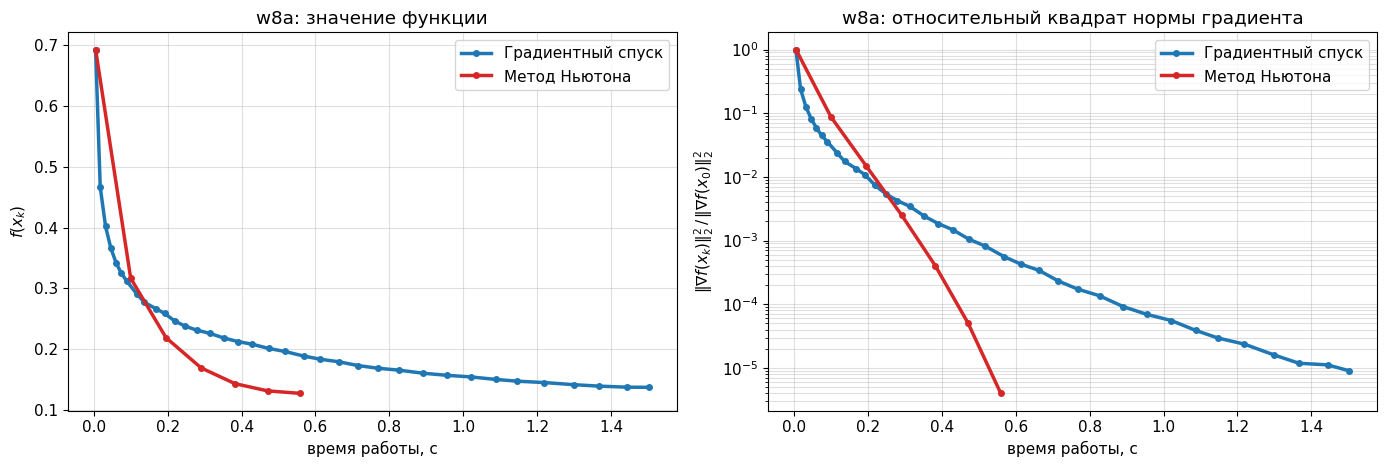

In [6]:
A, b = experiments.load_dataset('data/w8a.txt')
print('m = {}, n = {}, nnz = {}'.format(*A.shape, A.nnz))
res = experiments.run_task8(A, b)
experiments.plot_task8(res, 'w8a')

**w8a** ($m \gg n = 300$). Метод Ньютона сошёлся за 6 итераций и ≈0.6 с, градиентный спуск — за 35 итераций и ≈1.5 с. В самом начале (первые ≈0.2 с) градиентный спуск выигрывает: его итерация дешевле, и уже первые шаги заметно уменьшают $f$. Затем начинается квадратичная сходимость Ньютона: на правом графике его кривая в логарифмической шкале загибается вниз, тогда как у градиентного спуска — прямая (линейная сходимость). Гессиан здесь всего $300 \times 300$, поэтому итерация Ньютона стоит лишь в несколько раз дороже итерации GD. Обратите внимание: GD остановился с $f \approx 0.1371$, а Ньютон — с $f \approx 0.1271$. Относительный критерий $10^{-5}$ по норме градиента для плохо обусловленной задачи не гарантирует малой невязки по функции.


#### gisette

m = 6000, n = 5000, nnz = 29729997 (плотность 99.1%)


 Градиентный спуск:              success, итераций:  1399, время:  604.37 с, f* = 0.010589


     Метод Ньютона:              success, итераций:     6, время:   18.83 с, f* = 0.005254


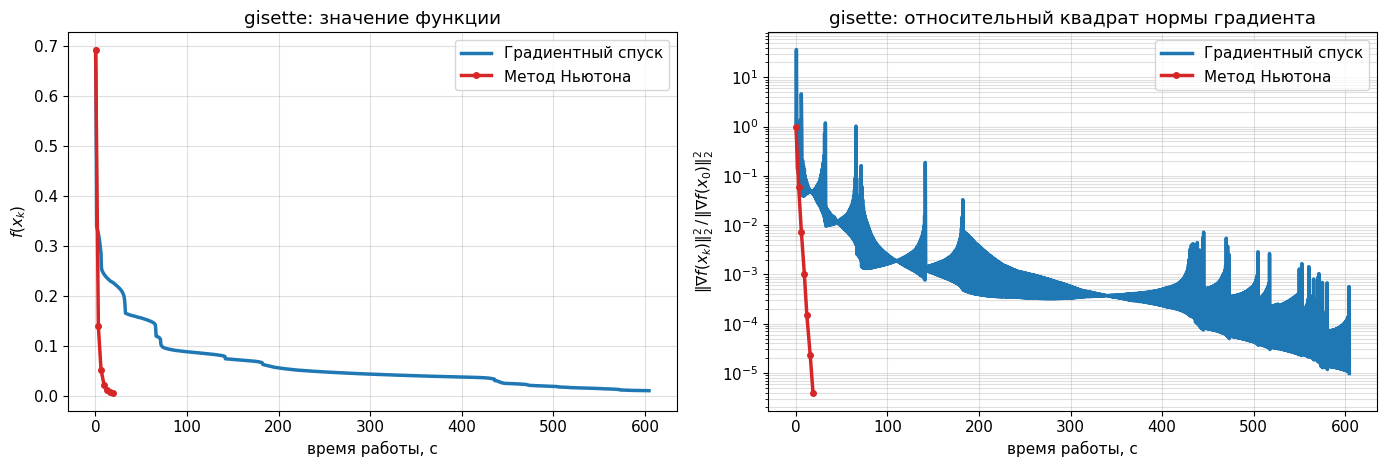

In [7]:
A, b = experiments.load_dataset('data/gisette_scale.bz2')
print('m = {}, n = {}, nnz = {} (плотность {:.1%})'.format(*A.shape, A.nnz, A.nnz / np.prod(A.shape)))
res = experiments.run_task8(A, b)
experiments.plot_task8(res, 'gisette')

**gisette** ($n = 5000$, плотная матрица). Здесь разница максимальна: Ньютону хватило **6 итераций и ≈19 с**, градиентному спуску — **1399 итераций и ≈600 с**, причём GD остановился с вдвое большим значением функции ($0.0106$ против $0.0053$). Задача очень плохо обусловлена: $n$ почти равно $m$, а $\lambda = 1/m$ очень мал. Норма градиента у GD сильно осциллирует (зигзаг поперёк «оврага», как в задании 3) и убывает очень медленно. Итерация Ньютона дорогая — построение гессиана $O(mn^2)$ и Холецкий $O(n^3)$ при $n = 5000$ занимают несколько секунд. Но эта стоимость с большим запасом окупается малым числом итераций: Ньютон не чувствителен к обусловленности задачи.


#### real-sim

m = 72309, n = 20958, nnz = 3709083 (плотность 0.245%)
Память под плотный гессиан n x n: 3.27 ГБ


 Градиентный спуск:              success, итераций:   103, время:   26.78 с, f* = 0.145471


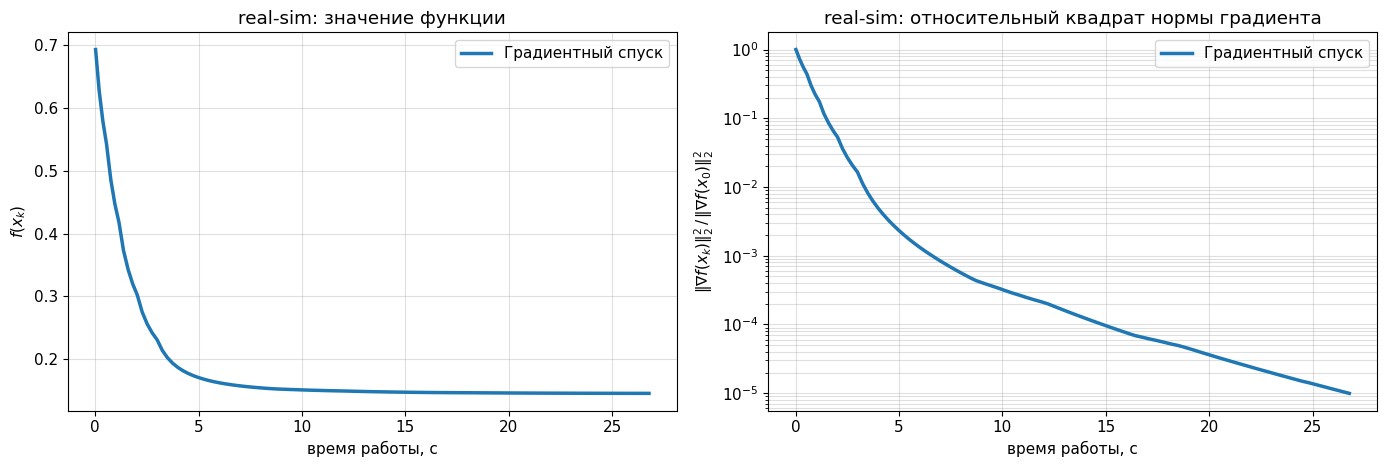

In [8]:
A, b = experiments.load_dataset('data/real-sim.bz2')
m, n = A.shape
print('m = {}, n = {}, nnz = {} (плотность {:.3%})'.format(m, n, A.nnz, A.nnz / (m * n)))
print('Память под плотный гессиан n x n: {:.2f} ГБ'.format(n * n * 8 / 2**30))
res = experiments.run_task8(A, b, methods=('gd',))
experiments.plot_task8(res, 'real-sim')

**real-sim** ($n = 20\,958$, очень разреженная матрица). Метод Ньютона здесь не запускался: плотный гессиан занимает ≈3.3 ГБ (плюс столько же на разложение Холецкого), а его построение и разложение стоили бы $O(n^3) \approx 10^{13}$ операций на итерацию. Градиентный спуск же работает с $A$ только через умножения на вектор за $O(\mathrm{nnz}(A))$, требует $O(\mathrm{nnz}(A) + m + n)$ памяти и сошёлся за 103 итерации и ≈27 с. Задача хорошо обусловлена (разреженные tf-idf признаки), функция почти перестаёт меняться уже через ≈7 с.


### Общие выводы по заданию 8

* **Метод Ньютона** сходится за очень малое число итераций (6 на w8a и gisette), не зависящее от обусловленности задачи; вблизи решения сходимость квадратичная. Но итерация стоит $O(mn^2 + n^3)$ времени и $O(n^2)$ памяти. Поэтому Ньютон — лучший выбор, когда **размерность $n$ невелика** (сотни — несколько тысяч), особенно для **плохо обусловленных** задач (gisette) и когда нужна высокая точность.
* **Градиентный спуск** делает дешёвые итерации за $O(\mathrm{nnz}(A))$ и требует памяти лишь под данные и несколько векторов длины $m$, $n$. Он хорошо использует разреженность, но сходится линейно со скоростью, зависящей от $\kappa$: на плохо обусловленной gisette — в 30 раз медленнее Ньютона по времени. Градиентный спуск — единственный реальный вариант при **большом $n$** (real-sim: Ньютону не хватает памяти), а также если нужна лишь умеренная точность: на первых долях секунды он уменьшает функцию быстрее Ньютона (w8a).
* На практике между ними лежат методы, сочетающие плюсы обоих (квазиньютоновские L-BFGS, неточный метод Ньютона с сопряжёнными градиентами, использующий только произведения гессиана на вектор), — они и применяются для логистической регрессии в больших размерностях.


# Оформление и проверка задания

## Что сдавать

Результатом выполнения задания являются:

1. Файлы `optimization.py` и `oracles.py` с реализованными методами и оракулами.
2. Полные исходные коды для проведения экспериментов и рисования всех графиков. Все результаты должны быть воспроизводимыми; если вы используете случайность — зафиксируйте `seed`.
3. Отчёт в формате `.ipynb` о проведённых исследованиях.

## Требования к отчёту

Каждый эксперимент (задания 3, 4 и 8) оформите в виде отдельного раздела отчёта. Для каждого эксперимента необходимо сначала написать его описание: какие функции оптимизируются, каким образом генерируются данные, какие методы и с какими параметрами используются. Далее должны быть представлены результаты соответствующего эксперимента — графики, таблицы и т. д. Наконец, после результатов должны быть написаны ваши выводы: какая зависимость наблюдается и почему.

**Важно:** отчёт не должен содержать много кода. Каждый график должен быть прокомментирован: что на нём изображено и какие выводы можно сделать из этого эксперимента. У графиков обязательно должны быть подписаны оси; если на графике нарисовано несколько кривых, должна быть легенда. Сами линии следует рисовать достаточно толстыми, чтобы они были хорошо видимыми.

## Проверка и оценивание

Перед отправкой задания обязательно убедитесь, что ваша реализация проходит автоматические предварительные тесты `presubmit_tests.py`, выданные вместе с заданием. Для этого запустите следующую команду:

```
python -m pytest presubmit_tests.py
```

**Важно:** решения, которые не будут проходить тесты `presubmit_tests.py`, будут автоматически оценены в **0 баллов**. Проверяющий не будет разбираться, почему ваш код не работает, и читать ваш отчёт.

Оценка за задание будет складываться из двух частей:

1. Правильность и эффективность реализованного кода — оценивается автоматически с помощью независимых тестов (отличных от предварительных).
2. Качество отчёта — оценивается проверяющим. При этом оценка может быть субъективной и апелляции не подлежит.

За реализацию модификаций алгоритмов и хорошие дополнительные эксперименты могут быть начислены дополнительные баллы. Начисление этих баллов является субъективным и безапелляционным.

**Важно:** практическое задание выполняется самостоятельно. Если вы получили ценные советы (по реализации или проведению экспериментов) от другого студента, об этом должно быть явно написано в отчёте. В противном случае «похожие» решения считаются плагиатом, и все задействованные студенты (в том числе те, у кого списали) будут сурово наказаны.